**Topic: The Relationship Between Median Household Income and COVID-19 Mortality Across U.S. States**

**Research question**: Was 2019 state-level median household income associated with cumulative COVID-19 mortality rates across the 50 U.S. states and the District of Columbia?

**Hypothesis**: States with higher 2019 median household income tended to have lower cumulative COVID-19 mortality rates (measured as deaths per 100,000 residents).

**Data Collection**

1. COVID-19 cases and deaths by U.S. state: New York Times COVID-19 data from Kaggle.

URL: https://www.kaggle.com/datasets/gniwnyc/nytimescovid19usdataset?select=us-states.csv

File: `covid_us_states.csv`.

Key variables: `date`, `state`, `cases`, `deaths`.

Sample size: 61,942 rows * 5 columns

Data format: CSV.

2. 2019 median household income: U.S. Census Bureau, ACS 1-Year Estimates Subject Table S1901.

URL: https://data.census.gov/table/ACSST1Y2019.S1901?q=median+household+income+by+state

File: `acs_2019_median_household_income.csv`.

Key variables: state columns, household median income estimate.

Sample size: 17 rows * 417 columns

Data format: CSV.

3. 2019 state population: U.S. Census Bureau, ACS 1-Year Estimates Detailed Table B01003.

URL: https://data.census.gov/table?q=ACSDT1Y2019.B01003&g=010XX00US$0400000&y=2019

File: `acs_2019_state_population.csv`.

Key variables: state columns, total population estimate.

Sample size: 1 row * 105 columns

Data format: CSV.

Join Key:

These three datasets are integrated using the `state` variable.

Known unknowns or gaps in the raw data:
- ACS estimates include margins of error; however, point estimates were used in this project to maintain model simplicity.
- COVID-19 case counts are influenced by factors including reporting lags and differences in state reporting practices.
- Factors such as vaccination status, public health policies, and underlying health conditions are not considered in this project.

Although the raw COVID-19 dataset contains five columns of data, preprocessing generates several additional variables of analytical value, including cases per 100,000 residents, deaths per 100,000 residents, and case-fatality rate. Consequently, the final integrated analysis dataset comprises more than six variables.

**Data Cleaning and Preprocessing**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, linregress

In [2]:
covid_raw = pd.read_csv('covid_us_states.csv')
income_raw = pd.read_csv('acs_2019_median_household_income.csv')
population_raw = pd.read_csv('acs_2019_state_population.csv')

In [3]:
covid_raw.shape

(61942, 5)

In [4]:
income_raw.shape

(17, 417)

In [5]:
population_raw.shape

(1, 105)

In [6]:
states = ['Alabama','Alaska','Arizona','Arkansas','California','Colorado','Connecticut','Delaware','District of Columbia','Florida','Georgia','Hawaii','Idaho','Illinois','Indiana','Iowa','Kansas','Kentucky','Louisiana','Maine','Maryland','Massachusetts','Michigan','Minnesota','Mississippi','Missouri','Montana','Nebraska','Nevada','New Hampshire','New Jersey','New Mexico','New York','North Carolina','North Dakota','Ohio','Oklahoma','Oregon','Pennsylvania','Rhode Island','South Carolina','South Dakota','Tennessee','Texas','Utah','Vermont','Virginia','Washington','West Virginia','Wisconsin','Wyoming']

**1. COVID Data Cleaning**

In [7]:
covid_raw['date'] = pd.to_datetime(covid_raw['date'])

In [8]:
covid_raw = covid_raw[covid_raw['state'].isin(states)].drop_duplicates()

In [9]:
covid_clean = covid_raw.sort_values(['state', 'date']).groupby('state').tail(1)

In [10]:
covid_cutoff_date = covid_clean["date"].max()
print("COVID-19 data cutoff date:", covid_cutoff_date.date())

COVID-19 data cutoff date: 2023-03-23


In [11]:
covid_clean = covid_clean[['state', 'date', 'cases', 'deaths']]

**2. Income Data Cleaning**

In [12]:
income_raw['Label_clean'] = income_raw['Label (Grouping)'].astype(str).str.replace(' ', ' ', regex=False).str.strip()

In [13]:
median_row = income_raw.loc[income_raw['Label_clean'].eq('Median income (dollars)')].iloc[0]

In [14]:
records = []
for col, value in median_row.items():
    if '!!Households!!Estimate' in col:
        state = col.split('!!')[0]
        income = pd.to_numeric(str(value).replace(',', '').replace('$', '').strip(), errors='coerce')
        records.append({'state': state, 'median_household_income_2019': income})

In [15]:
income = pd.DataFrame(records)

**3. Population Data Cleaning**

In [16]:
population_raw = population_raw.iloc[0]

In [17]:
records = []
for col, value in population_raw.items():
    if col.endswith('!!Estimate'):
        state = col.split('!!')[0]
        population = pd.to_numeric(str(value).replace(',', '').strip(), errors='coerce')
        records.append({'state': state, 'population_2019': population})

In [18]:
population = pd.DataFrame(records)

**4. Integration**

In [19]:
merged = covid_clean.merge(income, on='state', how='inner', validate="one_to_one").merge(population, on='state', how='inner', validate="one_to_one")

In [20]:
merged = merged[merged['state'].isin(states)].copy()

**5. Standardization**

In [21]:
merged['cases_per_100k'] = merged['cases'] / merged['population_2019'] * 100000

In [22]:
merged['deaths_per_100k'] = merged['deaths'] / merged['population_2019'] * 100000

In [23]:
merged['case_fatality_rate_pct'] = merged['deaths'] / merged['cases'] * 100

In [24]:
merged['income_z'] = (merged['median_household_income_2019'] - merged['median_household_income_2019'].mean()) / merged['median_household_income_2019'].std(ddof=0)

In [25]:
merged['deaths_per_100k_z'] = (merged['deaths_per_100k'] - merged['deaths_per_100k'].mean()) / merged['deaths_per_100k'].std(ddof=0)

Data Validation

The ACS income and population dataset comprises 52 geographic units, as it includes Puerto Rico; in contrast, the COVID-19 dataset covers the 50 U.S. states and the District of Columbia but excludes Puerto Rico. Consequently, Puerto Rico was removed during the data integration process, resulting in a final analysis dataset containing 51 geographic units.

In [26]:
core_variables = [
    "state",
    "date",
    "cases",
    "deaths",
    "median_household_income_2019",
    "population_2019",
    "cases_per_100k",
    "deaths_per_100k",
    "case_fatality_rate_pct",
]

print("Geographic unit counts:")
print(f"  COVID dataset: {covid_clean['state'].nunique()}")
print(f"  Income dataset: {income['state'].nunique()}")
print(f"  Population dataset: {population['state'].nunique()}")
print(f"  Final merged dataset: {merged['state'].nunique()}")
print(f"  Final merged rows: {len(merged)}")

extra_income = sorted(set(income["state"]) - set(covid_clean["state"]))

extra_population = sorted(set(population["state"]) - set(covid_clean["state"]))

print("\nAdditional geographic units in the Census income dataset:")
print(extra_income if extra_income else "None")

print("\nAdditional geographic units in the Census population dataset:")
print(extra_population if extra_population else "None")

duplicate_states = merged["state"].duplicated().sum()

print("\nDuplicate states in the merged dataset:")
print(duplicate_states)

missing_values = merged[core_variables].isna().sum()

print("\nMissing values in core analytical variables:")
print(missing_values)

Geographic unit counts:
  COVID dataset: 51
  Income dataset: 52
  Population dataset: 52
  Final merged dataset: 51
  Final merged rows: 51

Additional geographic units in the Census income dataset:
['Puerto Rico']

Additional geographic units in the Census population dataset:
['Puerto Rico']

Duplicate states in the merged dataset:
0

Missing values in core analytical variables:
state                           0
date                            0
cases                           0
deaths                          0
median_household_income_2019    0
population_2019                 0
cases_per_100k                  0
deaths_per_100k                 0
case_fatality_rate_pct          0
dtype: int64


In [27]:
merged

,state,date,cases,deaths,median_household_income_2019,population_2019,cases_per_100k,deaths_per_100k,case_fatality_rate_pct,income_z,deaths_per_100k_z
0,Alabama,2023-03-23,1648385,21631,51734,4903185,33618.658076,441.162224,1.312254,-1.245544,1.250617
1,Alaska,2023-03-23,308893,1438,75463,731545,42224.743522,196.570273,0.465533,0.899687,-1.597485
2,Arizona,2023-03-23,2451062,33190,62055,7278717,33674.368711,455.986955,1.354107,-0.312470,1.423240
3,Arkansas,2023-03-23,1008303,13068,48952,3017804,33411.812033,433.030111,1.296039,-1.497052,1.155924
4,California,2023-03-23,12169158,104277,80440,39512223,30798.464566,263.910740,0.856896,1.349635,-0.813352
5,Colorado,2023-03-23,1771010,14245,77127,5758736,30753.450063,247.363310,0.804343,1.050121,-1.006036
6,Connecticut,2023-03-23,978456,12270,78833,3565287,27443.961734,344.151817,1.254017,1.204353,0.120999
7,Delaware,2023-03-23,332861,3352,70176,973764,34182.923172,344.231251,1.007027,0.421713,0.121924
8,District of Columbia,2023-03-23,178226,1432,92266,705749,25253.454132,202.904999,0.803474,2.418770,-1.523721
9,Florida,2023-03-23,7542869,87141,59227,21477737,35119.477438,405.727102,1.155277,-0.568136,0.838000


**Data Analysis**

In [28]:
eda_vars = ['median_household_income_2019', 'population_2019', 'cases_per_100k', 'deaths_per_100k', 'case_fatality_rate_pct']

In [29]:
highest_income_state = merged.loc[merged['median_household_income_2019'].idxmax(), ['state', 'median_household_income_2019']].to_dict()

In [30]:
lowest_income_state = merged.loc[merged['median_household_income_2019'].idxmin(), ['state', 'median_household_income_2019']].to_dict()

In [31]:
highest_mortality_state = merged.loc[merged['deaths_per_100k'].idxmax(), ['state', 'deaths_per_100k']].to_dict()

In [32]:
lowest_mortality_state = merged.loc[merged['deaths_per_100k'].idxmin(), ['state', 'deaths_per_100k']].to_dict()

In [33]:
extremes = {'Highest income state': highest_income_state,
            'Lowest income state': lowest_income_state,
            'Highest mortality state': highest_mortality_state,
            'Lowest mortality state': lowest_mortality_state
}
extremes

{'Highest income state': {'state': 'District of Columbia',
  'median_household_income_2019': 92266},
 'Lowest income state': {'state': 'Mississippi',
  'median_household_income_2019': 45792},
 'Highest mortality state': {'state': 'Arizona',
  'deaths_per_100k': 455.9869548438276},
 'Lowest mortality state': {'state': 'Hawaii',
  'deaths_per_100k': 130.73215657912579}}

In [34]:
pearson = pearsonr(merged['median_household_income_2019'], merged['deaths_per_100k'])

In [35]:
spearman = spearmanr(merged['median_household_income_2019'], merged['deaths_per_100k'])

In [36]:
reg = linregress(merged['median_household_income_2019'], merged['deaths_per_100k'])

In [37]:
print(f"Pearson Correlation: {pearson[0]:.4f} (p-value: {pearson[1]:.4e})")

print(f"Spearman Correlation: {spearman[0]:.4f} (p-value: {spearman[1]:.4e})")

print(f"Linear Regression:")
print(f"  Slope: {reg.slope:.4f}")
print(f"  Intercept: {reg.intercept:.4f}")
print(f"  R-squared: {reg.rvalue**2:.4f}")
print(f"  p-value: {reg.pvalue:.4e}")

Pearson Correlation: -0.6113 (p-value: 1.8865e-06)
Spearman Correlation: -0.6492 (p-value: 2.5564e-07)
Linear Regression:
  Slope: -0.0047
  Intercept: 644.7022
  R-squared: 0.3737
  p-value: 1.8865e-06


**Visualization**

**Visualization 1: Distribution analysis**

This histogram shows how cumulative COVID-19 mortality rates are distributed across states.

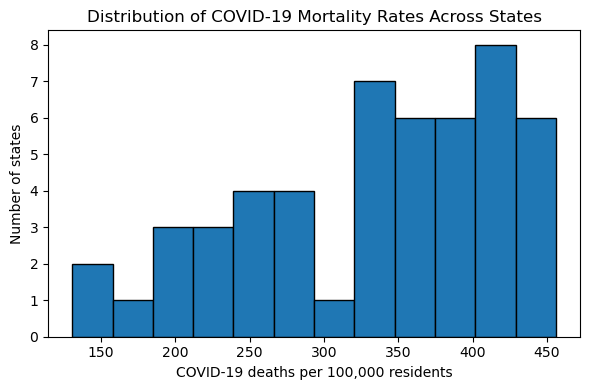

In [38]:
plt.figure(figsize=(6, 4))
plt.hist(merged['deaths_per_100k'], bins=12, edgecolor='black')
plt.xlabel('COVID-19 deaths per 100,000 residents')
plt.ylabel('Number of states')
plt.title('Distribution of COVID-19 Mortality Rates Across States')
plt.tight_layout()
plt.show()

**Visualization 2: Relational analysis**

This scatter plot directly tests the project hypothesis by comparing median household income in 2019 with the cumulative number of COVID-19 deaths per 100,000 residents.

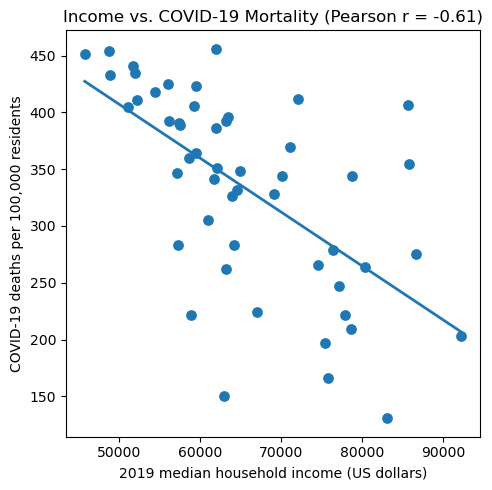

In [39]:
plt.figure(figsize=(5, 5))
x = merged['median_household_income_2019']
y = merged['deaths_per_100k']
reg = linregress(x, y)
plt.scatter(x, y, s=45)
xx = np.linspace(x.min(), x.max(), 100)
plt.plot(xx, reg.intercept + reg.slope * xx, linewidth=2)
plt.xlabel('2019 median household income (US dollars)')
plt.ylabel('COVID-19 deaths per 100,000 residents')
plt.title(f'Income vs. COVID-19 Mortality (Pearson r = {pearson.statistic:.2f})')
plt.tight_layout()
plt.show()

**Visualization 3: Correlation heatmap**

This heatmap summarizes the co-variation among income, population, case rates, death rates, and case fatality rates within the integrated dataset.

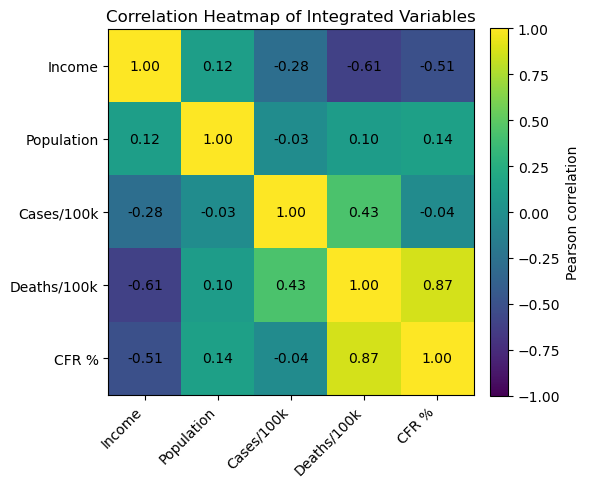

In [40]:
corr = merged[['median_household_income_2019', 'population_2019', 'cases_per_100k', 'deaths_per_100k', 'case_fatality_rate_pct']].corr()
plt.figure(figsize=(6, 6))
im = plt.imshow(corr, vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04, label='Pearson correlation')
labels = ['Income', 'Population', 'Cases/100k', 'Deaths/100k', 'CFR %']
plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
plt.yticks(range(len(labels)), labels)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
plt.title('Correlation Heatmap of Integrated Variables')
plt.tight_layout()
plt.show()

**Visualization 4: Significant maximum and minimum observations**

This ranked bar chart highlights the five lowest and five highest mortality states.

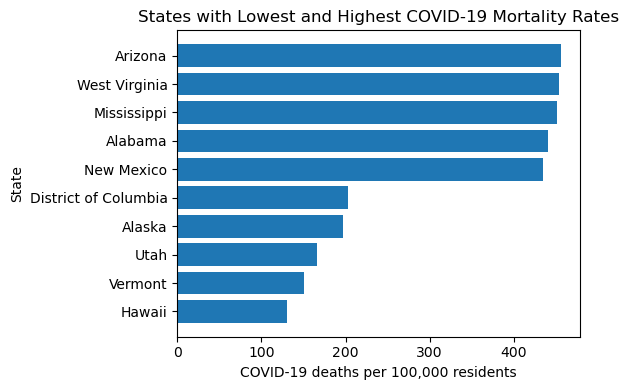

In [41]:
ranked = pd.concat([merged.nsmallest(5, 'deaths_per_100k'), merged.nlargest(5, 'deaths_per_100k')]).sort_values('deaths_per_100k')
plt.figure(figsize=(6, 4))
plt.barh(ranked['state'], ranked['deaths_per_100k'])
plt.xlabel('COVID-19 deaths per 100,000 residents')
plt.ylabel('State')
plt.title('States with Lowest and Highest COVID-19 Mortality Rates')
plt.tight_layout()
plt.show()

**Conclusions**

The integrated dataset comprises 51 state-level observations after integrating data on COVID-19 outcomes, 2019 household income, and 2019 population estimates.

This dataset reveals a negative correlation between 2019 median household income and the cumulative COVID-19 mortality rate (Pearson Correlation = -0.6113 and Spearman Correlation = -0.6492). Simple linear regression analysis indicates that for every $10,000 increase in median household income, the number of deaths per 100,000 residents decreases by approximately 47.5 (R-squared = 0.37).

**Limitations**

While this evidence is consistent with the project hypothesis, it should not be interpreted as establishing a causal relationship. State-level income may be correlated with other significant factors influencing COVID-19 outcomes, such as vaccination status, public health policies, and underlying health conditions.

**Suggested Next Steps**

Control variables should be incorporated and multivariate regression models should be constructed to enhance the persuasiveness of future studies.